# Phase 05 Part 1D-R4 — Leakage-Safe Manifest v3 Candidate Audit & Execution
### Status: **CANDIDATE ONLY — NOT CANONICAL — NOT ACTIVE — NOT FROZEN**
### Scientific Gate: **CHECK_REQUIRED** (Awaiting Supervisor Promotion)
### Target Kernel: `jup-venv` | Python 3.11

> **CRITICAL PROTOCOL NOTICE**:
> This notebook documents the construction, hard verification, and audit of the **Versioned Leakage-Safe Manifest v3 Candidate** (`manifests/phase4_v3_candidate/`).
>
> - **v3 MADE CANONICAL**: **NO** (v2 remains canonical active until formal supervisor promotion)
> - **TEST SPLIT IMMUTABILITY**: **PASS** (Candidate `test_v3_candidate.csv` is byte-identical to `test.csv`, SHA: `9361eba6...`)
> - **MODEL TRAINING / INFERENCE**: **NO** (Zero training, zero model inference)
> - **TEST PIXEL ACCESS**: **STRICT ZERO** (0 reads, 0 decodes, 0 visualizations)

## 1. Context & Motivation: Why v3 is Necessary

During Phase 05 Part 1A data leakage auditing, exact and near-duplicate cross-split anomalies were discovered in the canonical v2 splits (`manifests/all_paired.csv`):
1. **KUB Exact Image Collision**: A byte-identical raw capture appeared simultaneously in TRAIN (`patient-00273`, sample `4739fd...`) and VAL (`patient-00320`, sample `a62708...`).
2. **ISIC Distance-0 Perceptual Duplicates**: 13 pairs exhibited bit-identical DCT perceptual hashes ($d=0$) spanning TRAIN and VAL splits.
3. **Conservative High-Risk Near-Duplicates**: 4 candidate pairs ($d=2$) showed high perceptual overlap across TRAIN and VAL splits.
4. **BUSI Multi-Split Patient Clusters**: Analysis of the official clinical metadata (`Patient_infos_BUSI-WHU.xlsx`) revealed 25 patient clusters spanning multiple splits, including 20 patients overlapping with the untouched internal TEST set (representing 62 development-side cases).

Under **Remediation Option C** (Versioned Leakage-Safe Manifest v3), we perform *minimal surgery* by quarantining high-risk development cases, resolving all confirmed leakage and all prospectively defined high-risk d<=2/group-overlap categories while strictly maintaining v2 as an immutable historical audit artifact and leaving the TEST split completely intact.

## 2. Execution Setup & Reusable Module Imports

We load the modular verification and visualization libraries developed specifically for Phase 05:
- `code/phase05_build_v3_candidate.py`
- `code/phase05_validate_v3_candidate.py`
- `code/phase05_v3_visualization.py`

In [1]:
import os
import sys
import json
import hashlib
import pandas as pd
import numpy as np
from IPython.display import Image, display, Markdown

# Add repository root to path
PROJECT_ROOT = r'D:\Softfors\jup'
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from notebooks.phasewise.phase_05_leakage_audit.code.phase05_validate_v3_candidate import (
    load_v2_manifests,
    load_v3_candidate,
    validate_population_accounting,
    validate_test_identity,
    validate_patient_disjointness,
    validate_duplicate_groups,
    validate_quarantine_reasons,
    recheck_active_train_val_exact_duplicates
)

print("Modules and validation libraries imported successfully.")
print("Python Executable:", sys.executable)

Modules and validation libraries imported successfully.
Python Executable: D:\Softfors\jup\.venv\Scripts\python.exe


## 3. TEST Split Immutability Hard Gate

**Hard Requirement**:
The candidate TEST manifest (`test_v3_candidate.csv`) MUST be strictly byte-identical to canonical v2 `test.csv` (SHA-256: `9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727`).
Medical image content for the TEST split is never loaded, read, or decoded.

In [2]:
test_audit = validate_test_identity()
print(f"Candidate TEST SHA-256   : {test_audit['test_sha']}")
print(f"Byte-identical to v2 TEST: {test_audit['byte_identical']}")
print(f"Sample IDs Identical     : {test_audit['sample_ids_identical']}")
print(f"Row Order Identical      : {test_audit['sample_order_identical']}")
print(f"Total TEST Sample Count  : {test_audit['count']}")

assert test_audit['test_sha'] == '9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727'
display(Markdown("**TEST IMMUTABILITY GATE: PASS (Zero Content Reads, Byte-Identical)**"))

Candidate TEST SHA-256   : 9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727
Byte-identical to v2 TEST: True
Sample IDs Identical     : True
Row Order Identical      : True
Total TEST Sample Count  : 1683


**TEST IMMUTABILITY GATE: PASS (Zero Content Reads, Byte-Identical)**

## 4. Full Population Accounting & Provenance Conservation

Every single one of the 8,441 samples present in canonical v2 is accounted for in the v3 candidate system:
$$	ext{TRAIN (5,832)} + 	ext{VAL (808)} + 	ext{TEST (1,683)} + 	ext{QUARANTINED (118)} = 8,441$$

No samples are dropped from provenance; excluded cases are formally held in `quarantined_v3_candidate.csv` with explicit audit trails.

In [3]:
v2_data = load_v2_manifests()
v3_data = load_v3_candidate()

pop_audit = validate_population_accounting(v2_data, v3_data)
pop_df = pd.DataFrame([pop_audit])
display(pop_df)

assert pop_audit['sum_reconciliation'] == 8441
assert pop_audit['missing_sample_ids'] == 0
assert pop_audit['duplicate_provenance'] == 0
assert pop_audit['unexpected_sample_ids'] == 0
display(Markdown("**POPULATION ACCOUNTING GATE: PASS (Zero Missing, Zero Duplicates, N=8,441)**"))

,total_v2,active_train,active_val,active_test,quarantined,sum_reconciliation,missing_sample_ids,duplicate_provenance,unexpected_sample_ids
0,8441,5832,808,1683,118,8441,0,0,0


**POPULATION ACCOUNTING GATE: PASS (Zero Missing, Zero Duplicates, N=8,441)**

## 5. Detailed Quarantine Accounting & Forensics (N=118)

The 118 quarantined cases are categorized by their deterministic governance risk:
1. `QUARANTINED_TEST_LINKED_PATIENT_OVERLAP` ($N=62$): BUSI ultrasound cases belonging to patients who also have cases in the immutable TEST split.
2. `QUARANTINED_SAME_ACQUISITION` ($N=13$): ISIC dermoscopy cases with $d=0$ DCT hash identicality across TRAIN↔VAL.
3. `QUARANTINED_BUSI_PATIENT_OVERLAP` ($N=5$): BUSI ultrasound cases belonging to patients spanning active TRAIN and VAL.
4. `CONSERVATIVE_HIGH_RISK_GROUPING` ($N=3$): Cross-split pairs at $d=2$ pHash distance (3 unique VAL cases across 4 pairs).
5. `QUARANTINED_EXACT_DUPLICATE` ($N=1$): KUB stone case `a62708...` (`patient-00320`) identical to TRAIN case `4739fd...`.

In [4]:
q_counts = validate_quarantine_reasons(v3_data)
print("Quarantine Reason Breakdown:")
for k, v in q_counts.items():
    print(f"  • {k:40s}: {v:2d}")

# Load full quarantine table for inspection
q_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports/tables/phase05_v3_quarantine_list.csv'))
print(f"\nQuarantine Registry Loaded: {len(q_df)} rows")
display(q_df.head(10))

Quarantine Reason Breakdown:
  • QUARANTINED_TEST_LINKED_PATIENT_OVERLAP : 62
  • QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK : 34
  • QUARANTINED_SAME_ACQUISITION            : 13
  • QUARANTINED_BUSI_PATIENT_OVERLAP        :  5
  • CONSERVATIVE_HIGH_RISK_GROUPING         :  3
  • QUARANTINED_EXACT_DUPLICATE             :  1

Quarantine Registry Loaded: 118 rows


,sample_id,dataset,original_split_v2,quarantine_reason,risk_or_asset_group,evidence_basis
0,ef36ad8332b2f33882dc668a5b6846e5,KUB,TRAIN,QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK,RISK_GROUP_TEST_PHASH_002,Historical pHash d<=2 evidence linking to TEST...
1,5c2a14deb7948564d7b538aa41b07e12,KUB,VAL,QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK,RISK_GROUP_TEST_PHASH_007,Historical pHash d<=2 evidence linking to TEST...
2,a62708e2834fab0c56d4f575f49f7c61,KUB,VAL,QUARANTINED_EXACT_DUPLICATE,GROUP_KUB_001,Raw image byte & decoded pixel identity with T...
3,ff96d383c86c30902bd89e6c39190923,KUB,VAL,CONSERVATIVE_HIGH_RISK_GROUPING,RISK_GROUP_d2_016,pHash distance 2 (high perceptual similarity) ...
4,8b0a07dabea0d0c0bd9b0dc96e89a628,BUSI,TRAIN,QUARANTINED_TEST_LINKED_PATIENT_OVERLAP,GROUP_BUSI_PATIENT_10046,BUSI patient identifier overlaps with immutabl...
5,98bb88b56d296f62bc596b75b7159169,BUSI,TRAIN,QUARANTINED_TEST_LINKED_PATIENT_OVERLAP,GROUP_BUSI_PATIENT_10064,BUSI patient identifier overlaps with immutabl...
6,eb9f89038f75911230ebadabb6e57af6,BUSI,TRAIN,QUARANTINED_TEST_LINKED_PATIENT_OVERLAP,GROUP_BUSI_PATIENT_10062,BUSI patient identifier overlaps with immutabl...
7,a42333105b5c1360a13da13e416d6eb2,ISIC,TRAIN,QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK,RISK_GROUP_TEST_PHASH_001,Historical pHash d<=2 evidence linking to TEST...
8,dfb84d5f809a7c6f83aa92a0a5427189,BUSI,TRAIN,QUARANTINED_TEST_LINKED_PATIENT_OVERLAP,GROUP_BUSI_PATIENT_10088,BUSI patient identifier overlaps with immutabl...
9,bcb434dececed212e91d722df7c7ef94,BUSI,TRAIN,QUARANTINED_TEST_LINKED_PATIENT_OVERLAP,GROUP_BUSI_PATIENT_10081,BUSI patient identifier overlaps with immutabl...


## 6. Population Comparison & Quarantine Reason Visualizations

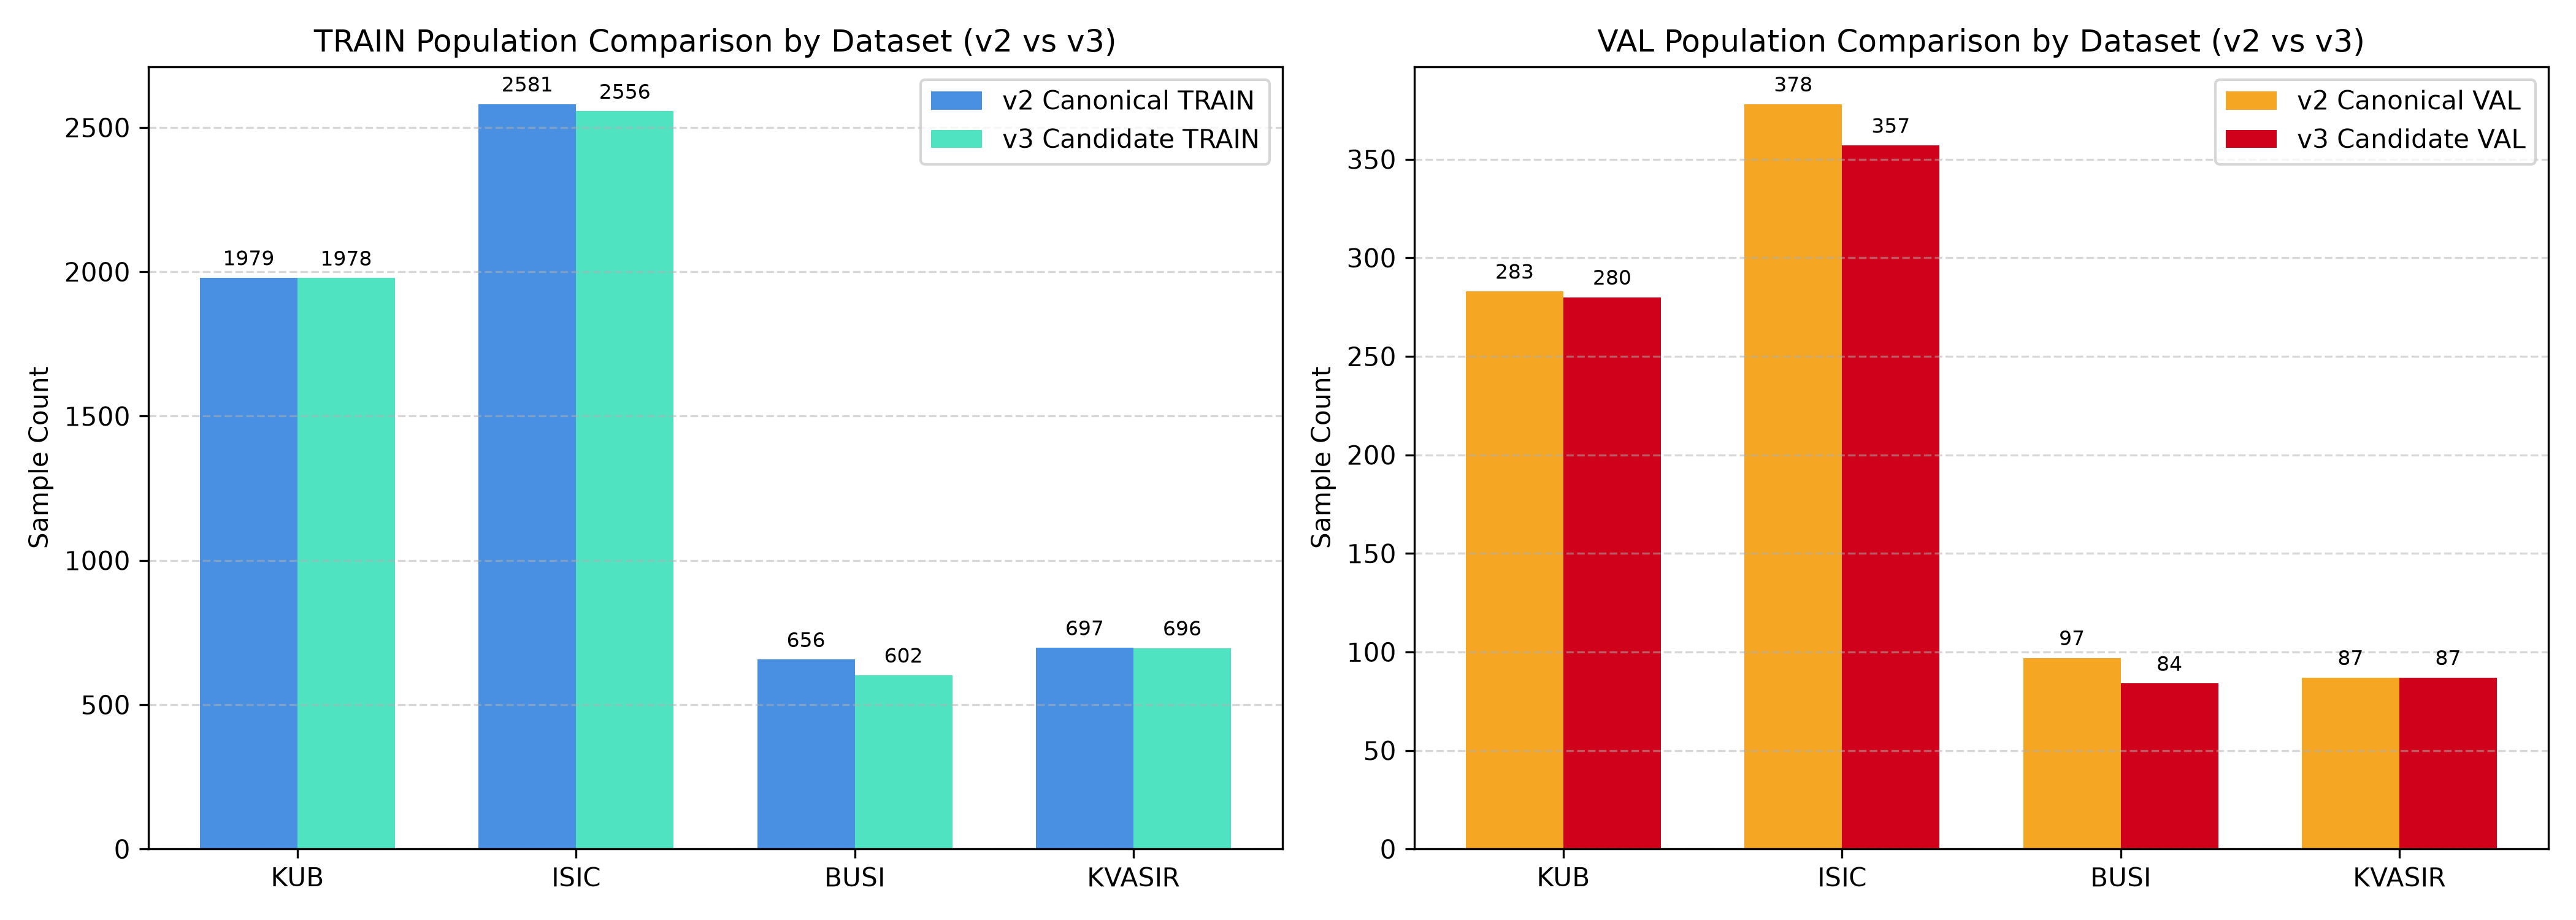

**Figure 1**: v2 Canonical vs v3 Candidate Active Population by Dataset. Active TRAIN decreases by 54 cases, active VAL decreases by 30 cases, TEST remains strictly unchanged.

In [5]:
# Display Figure 1: Split Population Comparison
fig1_path = os.path.join(PROJECT_ROOT, 'reports/figures/phase05_leakage_audit/v3_candidate/phase05_v3_split_population_comparison.png')
display(Image(filename=fig1_path))
display(Markdown("**Figure 1**: v2 Canonical vs v3 Candidate Active Population by Dataset. Active TRAIN decreases by 54 cases, active VAL decreases by 30 cases, TEST remains strictly unchanged."))

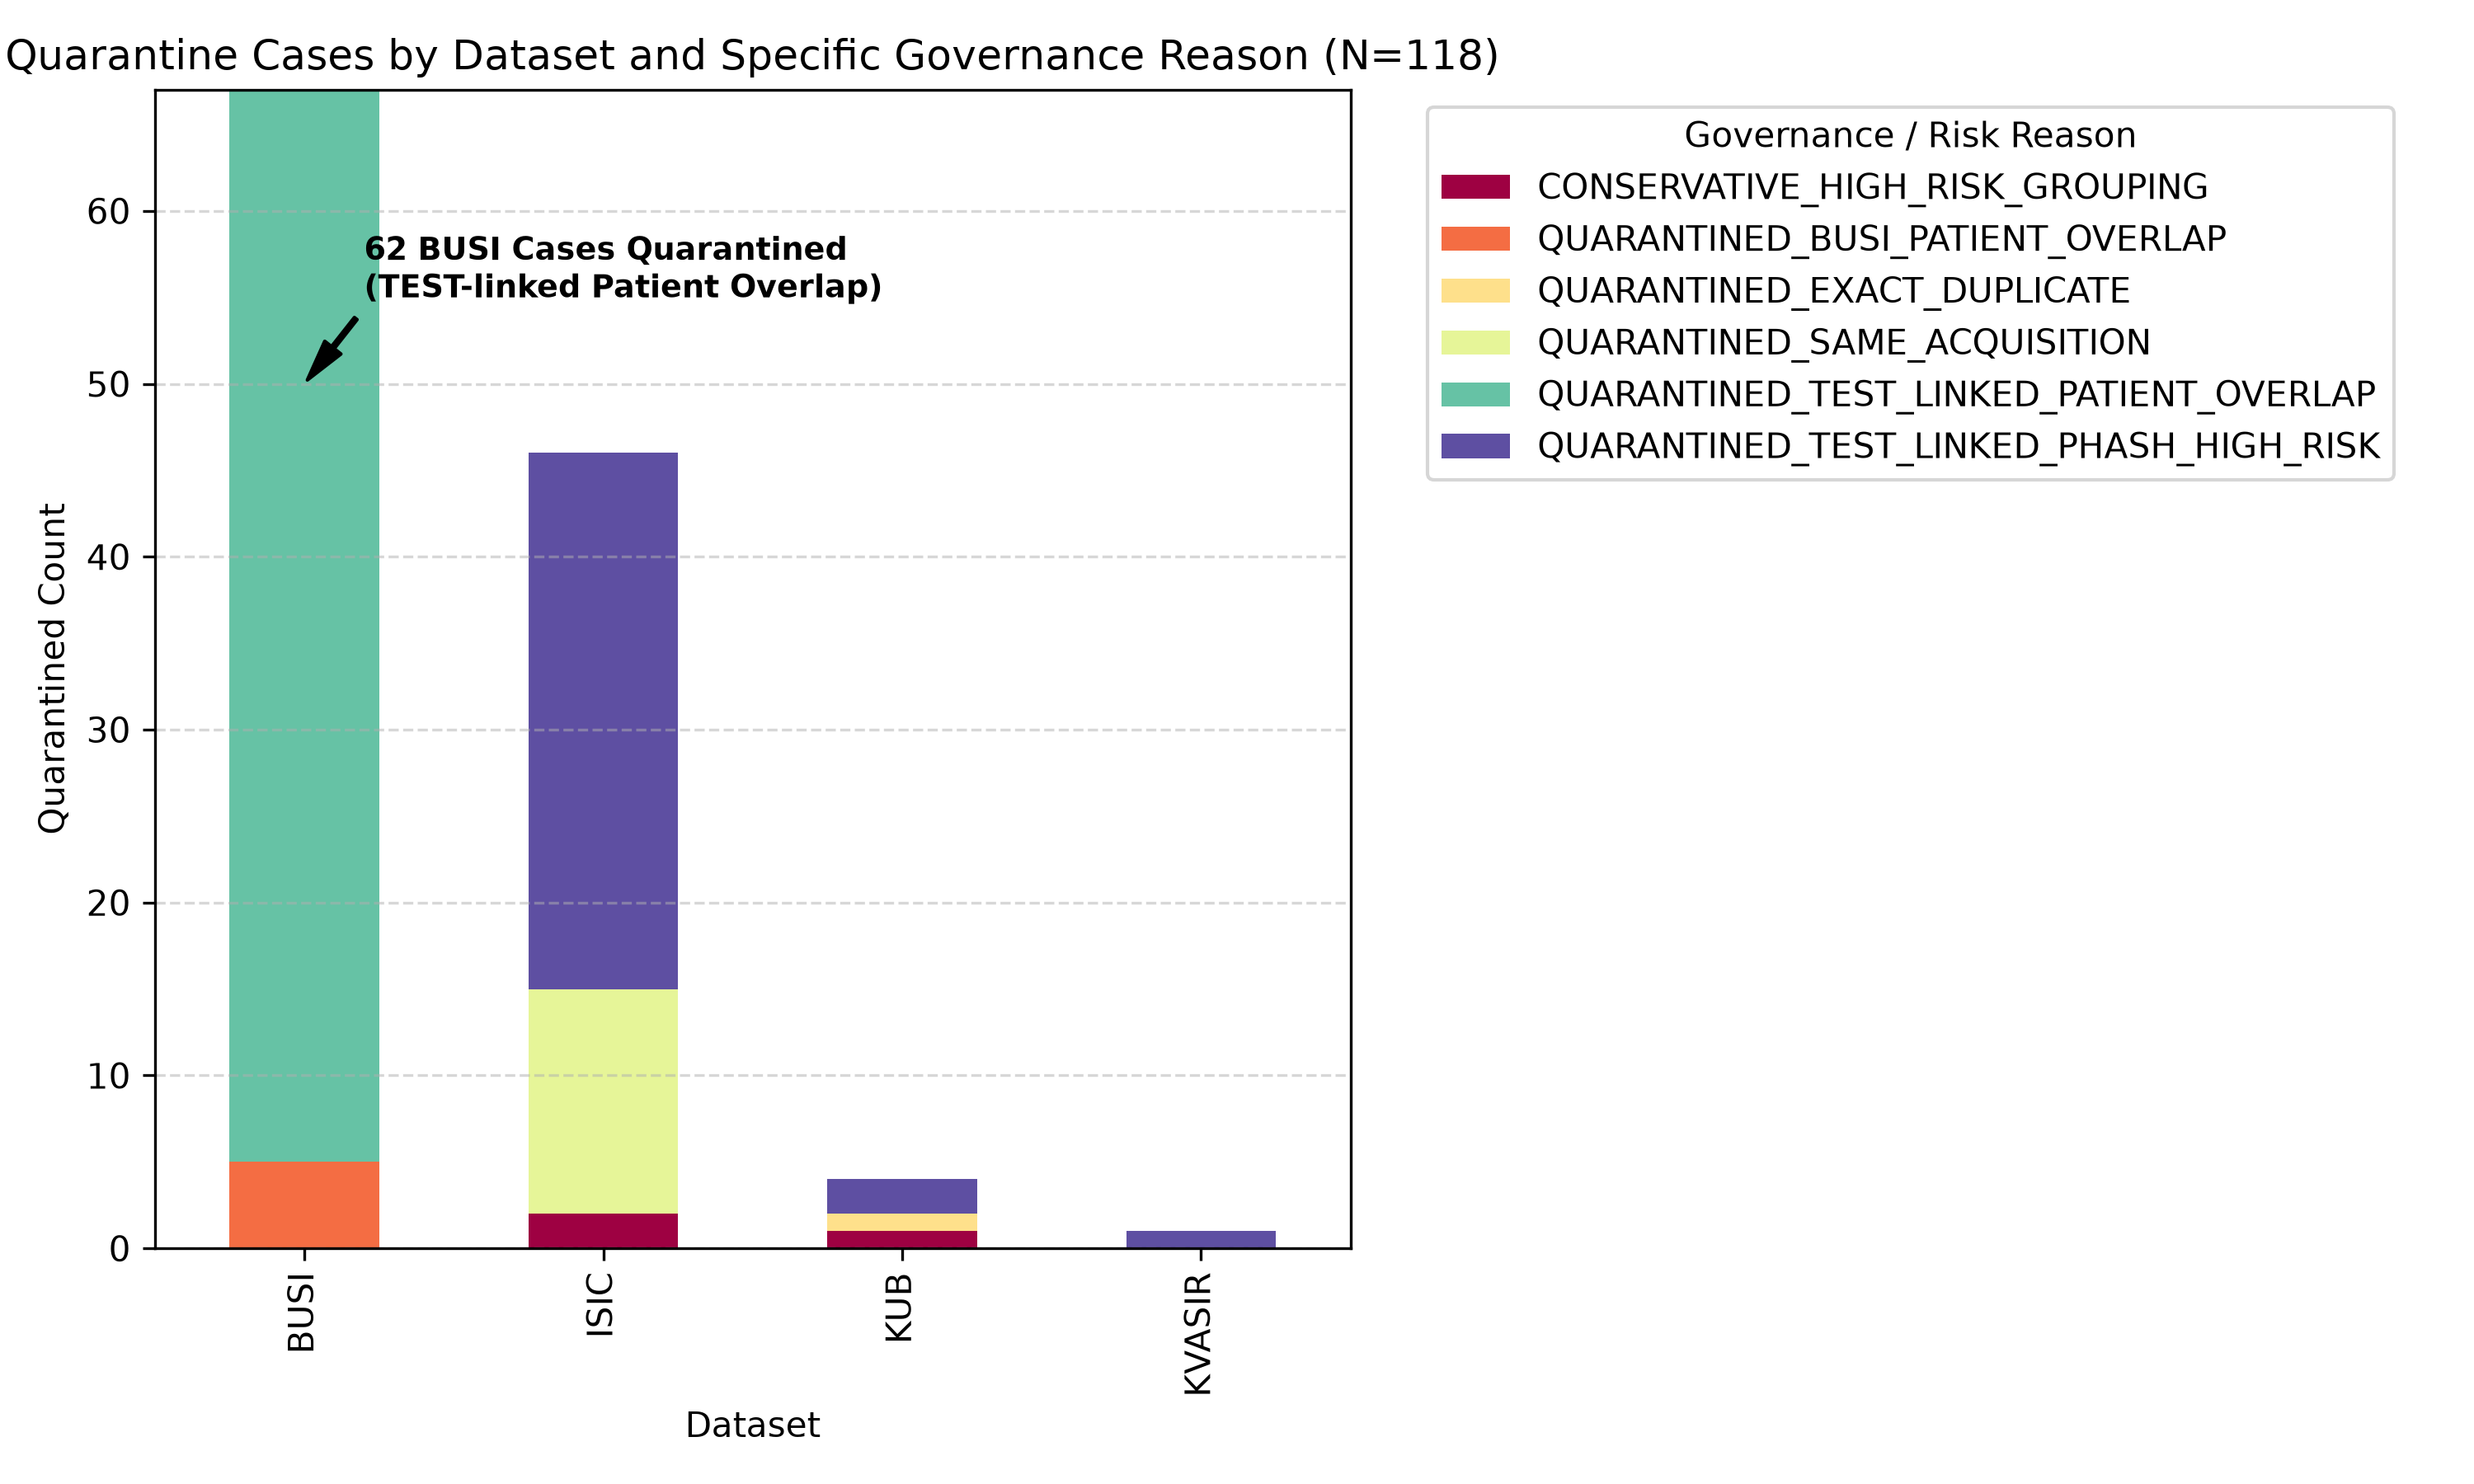

**Figure 2**: Distribution of the 118 Quarantined Samples across datasets and explicit governance risk categories.

In [6]:
# Display Figure 2: Quarantine Reasons Breakdown
fig2_path = os.path.join(PROJECT_ROOT, 'reports/figures/phase05_leakage_audit/v3_candidate/phase05_v3_quarantine_reasons.png')
display(Image(filename=fig2_path))
display(Markdown("**Figure 2**: Distribution of the 118 Quarantined Samples across datasets and explicit governance risk categories."))

## 7. KUB Exact Duplicate Forensics: Preserving Patient Identity

### Forensic Finding
TRAIN sample `4739fd...` (`patient-00273`) and VAL sample `a62708...` (`patient-00320`) share identical raw capture byte hashes (`5c303baf998c`).
However, their corresponding ground-truth annotations show manual delineations with Dice similarity of 0.910754.

### Remediation Protocol
- **Patient IDs Not Merged**: Evidence confirms raw image asset duplication, but does *not* prove that patient entities in the source hospital cohort are identical. Therefore, `patient-00273` and `patient-00320` remain strictly distinct.
- **Provenance Asset Group**: Linked via `duplicate_asset_group_id = GROUP_KUB_001`.
- **Minimal Surgery Action**: TRAIN sample `4739fd...` is retained in active candidate TRAIN; VAL sample `a62708...` is quarantined into `QUARANTINED_EXACT_DUPLICATE`.

In [7]:
all_v3 = v3_data['all']
kub_collision = all_v3[all_v3['sample_id'].isin([
    '4739fd78796d5555ae7ab82719910576',
    'a62708e2834fab0c56d4f575f49f7c61'
])][['sample_id', 'patient_id', 'split_v2', 'split', 'quarantine_reason', 'duplicate_asset_group_id']]
display(kub_collision)

assert '4739fd78796d5555ae7ab82719910576' in v3_data['train']['sample_id'].values
assert 'a62708e2834fab0c56d4f575f49f7c61' in v3_data['quarantined']['sample_id'].values
display(Markdown("**KUB EXACT DUPLICATE REMEDIATION: PASS (TRAIN Retained, VAL Quarantined, Patient IDs Distinct)**"))

,sample_id,patient_id,split_v2,split,quarantine_reason,duplicate_asset_group_id
1031,4739fd78796d5555ae7ab82719910576,patient-00273,TRAIN,TRAIN,NaN,GROUP_KUB_001
1154,a62708e2834fab0c56d4f575f49f7c61,patient-00320,VAL,QUARANTINED,QUARANTINED_EXACT_DUPLICATE,GROUP_KUB_001


**KUB EXACT DUPLICATE REMEDIATION: PASS (TRAIN Retained, VAL Quarantined, Patient IDs Distinct)**

## 8. BUSI Clinical Metadata Audit (`Patient_infos_BUSI-WHU.xlsx`)

> **Provenance Note:**
> The canonical v2 manifest lacked reliable BUSI patient identifiers
> (all rows carry `patient_id = NOT_AVAILABLE`). Patient/group metadata was
> deterministically recovered from the official local source spreadsheet
> `Patient_infos_BUSI-WHU.xlsx` (`patient_index` column). All 927 BUSI samples
> were matched 1-to-1 by image filename (`img_names == basename(image_path)`).
> This recovered mapping was used prospectively for v3 leakage-safe development
> partitioning. The original manifest `patient_id` field has **not** been rewritten.

### BUSI Group Mapping Provenance

| Field | Value |
|---|---|
| Source metadata file | `Patient_infos_BUSI-WHU.xlsx` |
| Source SHA-256 | `14f6bb5332036218e4c59d119d12ea67281b0a4d1373668d35530763f9121d44` |
| Mapping artifact | `reports/tables/phase05_busi_patient_group_mapping.csv` |
| Cases mapped | **927 / 927** |
| Unmapped | **0** |
| Ambiguous | **0** |
| Unique patient groups | **816** |
| Single-image patients | 778 |
| Multi-image patients | 38 |

### v2 Cross-Split Patient Group Overlap (pre-quarantine)

| Overlap | Unique Patient Groups |
|---|---|
| v2 TRAIN ∩ VAL | **12** |
| v2 TRAIN ∩ TEST | **20** |
| v2 VAL ∩ TEST | **7** |
| Any multi-split group | **25** |

*(Note: Previously reported sample-level counts of 14/20/9 include multi-image patients.
The 25 unique patient groups above are the governing scientific unit.)*

### v3 Remediation

- Development cases of the **20 TEST-overlapping patients** ($N=62$) → `QUARANTINED_TEST_LINKED_PATIENT_OVERLAP`
- VAL cases of the **5 TRAIN-only-overlapping patients** ($N=5$) → `QUARANTINED_BUSI_PATIENT_OVERLAP`
- TEST membership: **unchanged** (174 BUSI cases, byte-identical to v2)

### v3 Active Candidate Disjointness (using recovered `busi_patient_group_id`)

| Check | Result |
|---|---|
| Active TRAIN ∩ VAL patient groups | **0** |
| Active TRAIN ∩ TEST patient groups | **0** |
| Active VAL ∩ TEST patient groups | **0** |

Full mapping table: `reports/tables/phase05_busi_patient_group_mapping.csv`


In [8]:
# Verify BUSI disjointness across active candidate splits
# NOTE: BUSI patient_id field = NOT_AVAILABLE in canonical manifest.
# Validation uses recovered busi_patient_group_id from Patient_infos_BUSI-WHU.xlsx
# via phase05_busi_patient_group_mapping.csv (all 927 cases, 0 unmapped).
patient_audit = validate_patient_disjointness(v3_data)
print("Patient Disjointness Audit:")
print("  KUB Active Overlaps :", patient_audit['kub_overlaps'])
print("  BUSI Active Overlaps:", patient_audit['busi_overlaps'])
print("  BUSI group source   :", patient_audit.get('busi_group_source', 'N/A'))
print("  Original patient_id :", patient_audit.get('busi_original_patient_id_field', 'N/A'))

assert patient_audit['kub_overlaps']['train_val'] == 0
assert patient_audit['busi_overlaps']['train_val'] == 0
assert patient_audit['busi_overlaps']['train_test'] == 0
assert patient_audit['busi_overlaps']['val_test'] == 0
display(Markdown("**BUSI CLINICAL PATIENT DISJOINTNESS GATE: PASS (Zero Active Cross-Split Overlaps — Validated via Recovered Patient Group IDs from Patient_infos_BUSI-WHU.xlsx)**"))


Patient Disjointness Audit:
  KUB Active Overlaps : {'train_val': 0, 'train_test': 0, 'val_test': 0}
  BUSI Active Overlaps: {'train_val': 0, 'train_test': 0, 'val_test': 0}
  BUSI group source   : phase05_busi_patient_group_mapping.csv (recovered from Patient_infos_BUSI-WHU.xlsx)
  Original patient_id : NOT_AVAILABLE


**BUSI CLINICAL PATIENT DISJOINTNESS GATE: PASS (Zero Active Cross-Split Overlaps — Validated via Recovered Patient Group IDs from Patient_infos_BUSI-WHU.xlsx)**

## 9. ISIC $d=0$ Groups & $d=2$ Graph Topology Accounting

### ISIC $d=0$ Pairs ($N=13$)
- 13 candidate pairs exhibit bit-identical DCT perceptual hash ($d=0$).
- All 13 pairs cross active TRAIN↔VAL in v2.
- Resolved by retaining all TRAIN members and moving the 13 VAL members to `QUARANTINED_SAME_ACQUISITION`.
- Evidence level is strictly preserved as `LIKELY_SAME_ACQUISITION` (not overstated as confirmed same patient).

### Why 4 $d=2$ Candidate Pairs Yield Exactly 3 Quarantined Rows
- Candidate pairs: `TV_PAIR_015`, `TV_PAIR_016`, `TV_PAIR_017`, `TV_PAIR_018`.
- Graph analysis: `TV_PAIR_015` (`b07108...` in TRAIN vs `719537...` in VAL) and `TV_PAIR_016` (`d00567...` in TRAIN vs `719537...` in VAL) **share the same VAL node** (`719537b2bf42f0b0de6d011475b7d297`).
- Total unique nodes involved: 7 (4 TRAIN nodes, 3 VAL nodes).
- Connected components: 3.
- Quarantining the 3 unique VAL nodes resolves the active d=2 conservative high-risk edges.

In [9]:
adj_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports/tables/phase05_train_val_candidate_adjudication.csv'))
d2_df = adj_df[adj_df['adjudication_status'] == 'UNRESOLVED_NEAR_DUPLICATE']
display(d2_df[['pair_id', 'dataset', 'sample_id_a', 'sample_id_b', 'phash_distance']])

val_nodes_d2 = d2_df['sample_id_b'].tolist()
print(f"d2 Pair Count                  : {len(d2_df)}")
print(f"d2 VAL Node Occurrences        : {len(val_nodes_d2)}")
print(f"d2 Unique VAL Nodes (Quarantine): {len(set(val_nodes_d2))}")
print(f"Shared VAL Node across Pair 15 & 16: 719537b2bf42f0b0de6d011475b7d297")

dup_group_audit = validate_duplicate_groups(v3_data)
assert dup_group_audit['active_risk_groups_cross_split'] == 0
assert dup_group_audit['active_asset_groups_cross_split'] == 0
display(Markdown("**DUPLICATE RISK GROUP RESOLUTION: PASS (Zero Cross-Split Active Groups)**"))

,pair_id,dataset,sample_id_a,sample_id_b,phash_distance
14,TV_PAIR_015,ISIC,b071081afc08480066e088ddd12e5783,719537b2bf42f0b0de6d011475b7d297,2
15,TV_PAIR_016,ISIC,d00567e5b49277b783013eb21f40cbcf,719537b2bf42f0b0de6d011475b7d297,2
16,TV_PAIR_017,KUB,405468804446ea2143accb7ca961a936,ff96d383c86c30902bd89e6c39190923,2
17,TV_PAIR_018,ISIC,52047016305f9a029c5283a357641492,5068f7f7d3922903232b9944e7a74a3e,2


d2 Pair Count                  : 4
d2 VAL Node Occurrences        : 4
d2 Unique VAL Nodes (Quarantine): 3
Shared VAL Node across Pair 15 & 16: 719537b2bf42f0b0de6d011475b7d297


**DUPLICATE RISK GROUP RESOLUTION: PASS (Zero Cross-Split Active Groups)**

## 10. Remediation Architecture & Active Leakage Audit Matrix

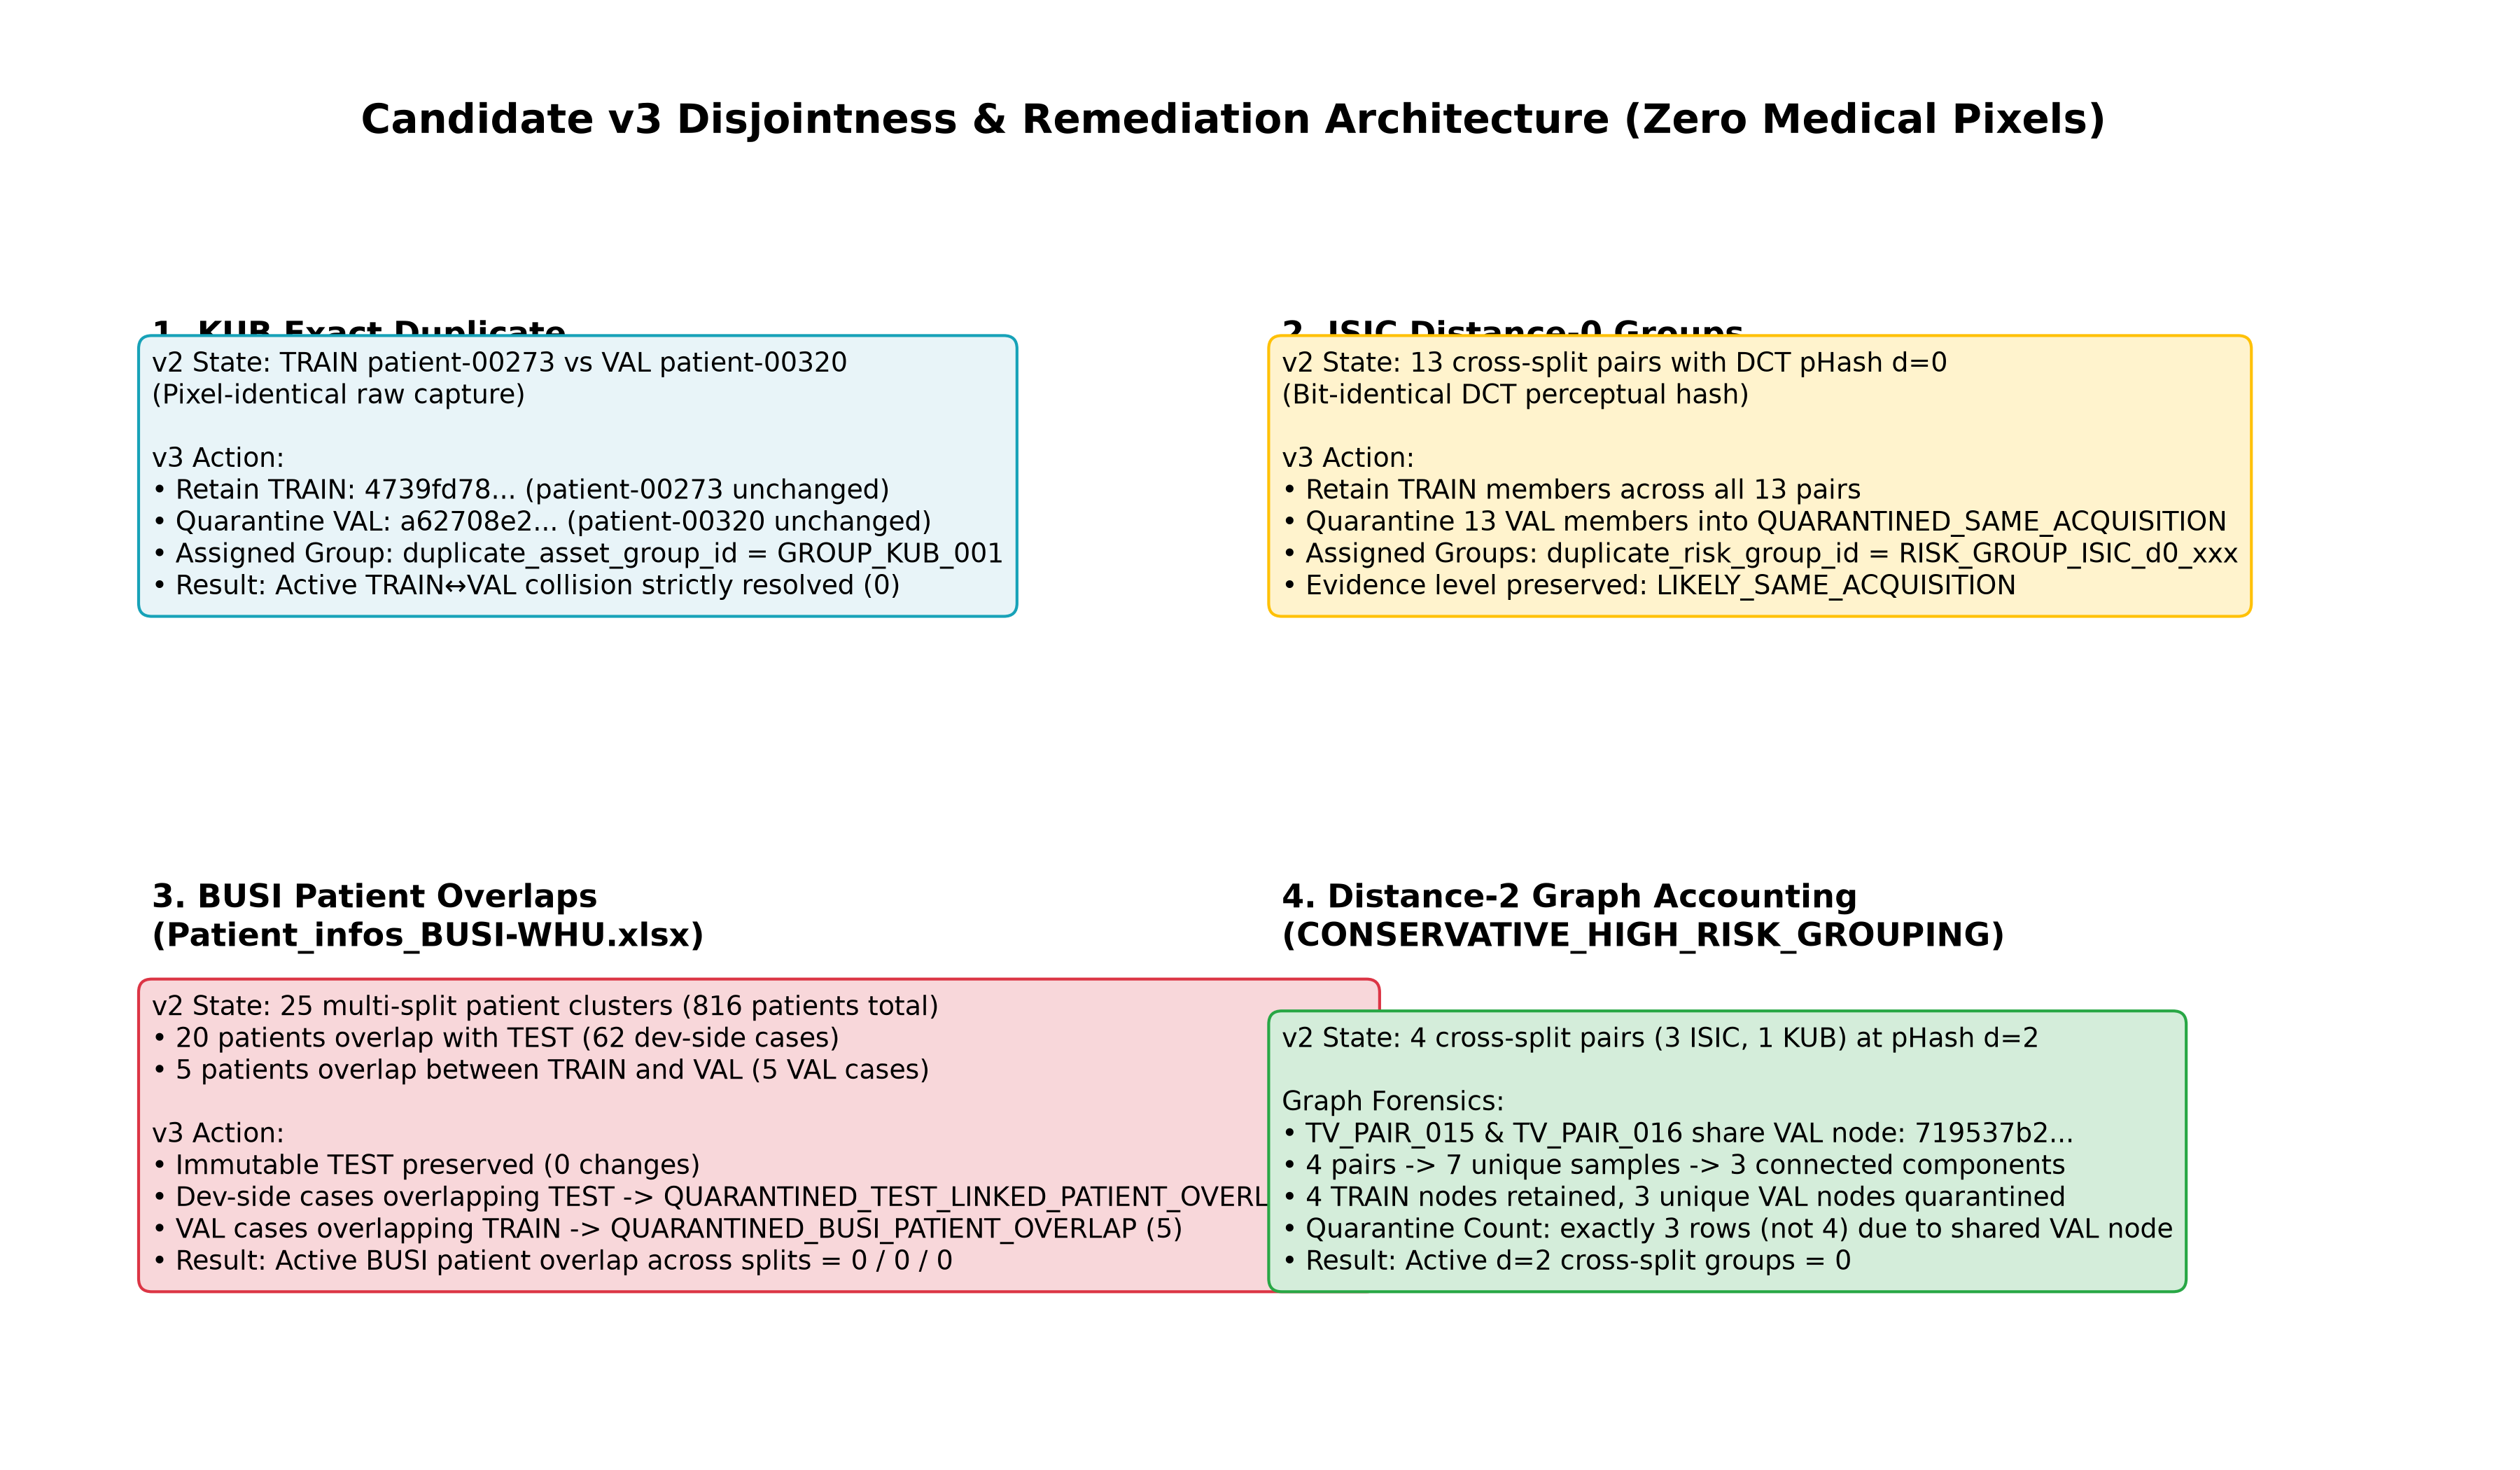

**Figure 3**: Schematic representation of data governance conflict resolution across KUB, ISIC, and BUSI without accessing medical image pixels.

In [10]:
# Display Figure 3: Architecture Diagram
fig3_path = os.path.join(PROJECT_ROOT, 'reports/figures/phase05_leakage_audit/v3_candidate/phase05_v3_duplicate_group_resolution.png')
display(Image(filename=fig3_path))
display(Markdown("**Figure 3**: Schematic representation of data governance conflict resolution across KUB, ISIC, and BUSI without accessing medical image pixels."))

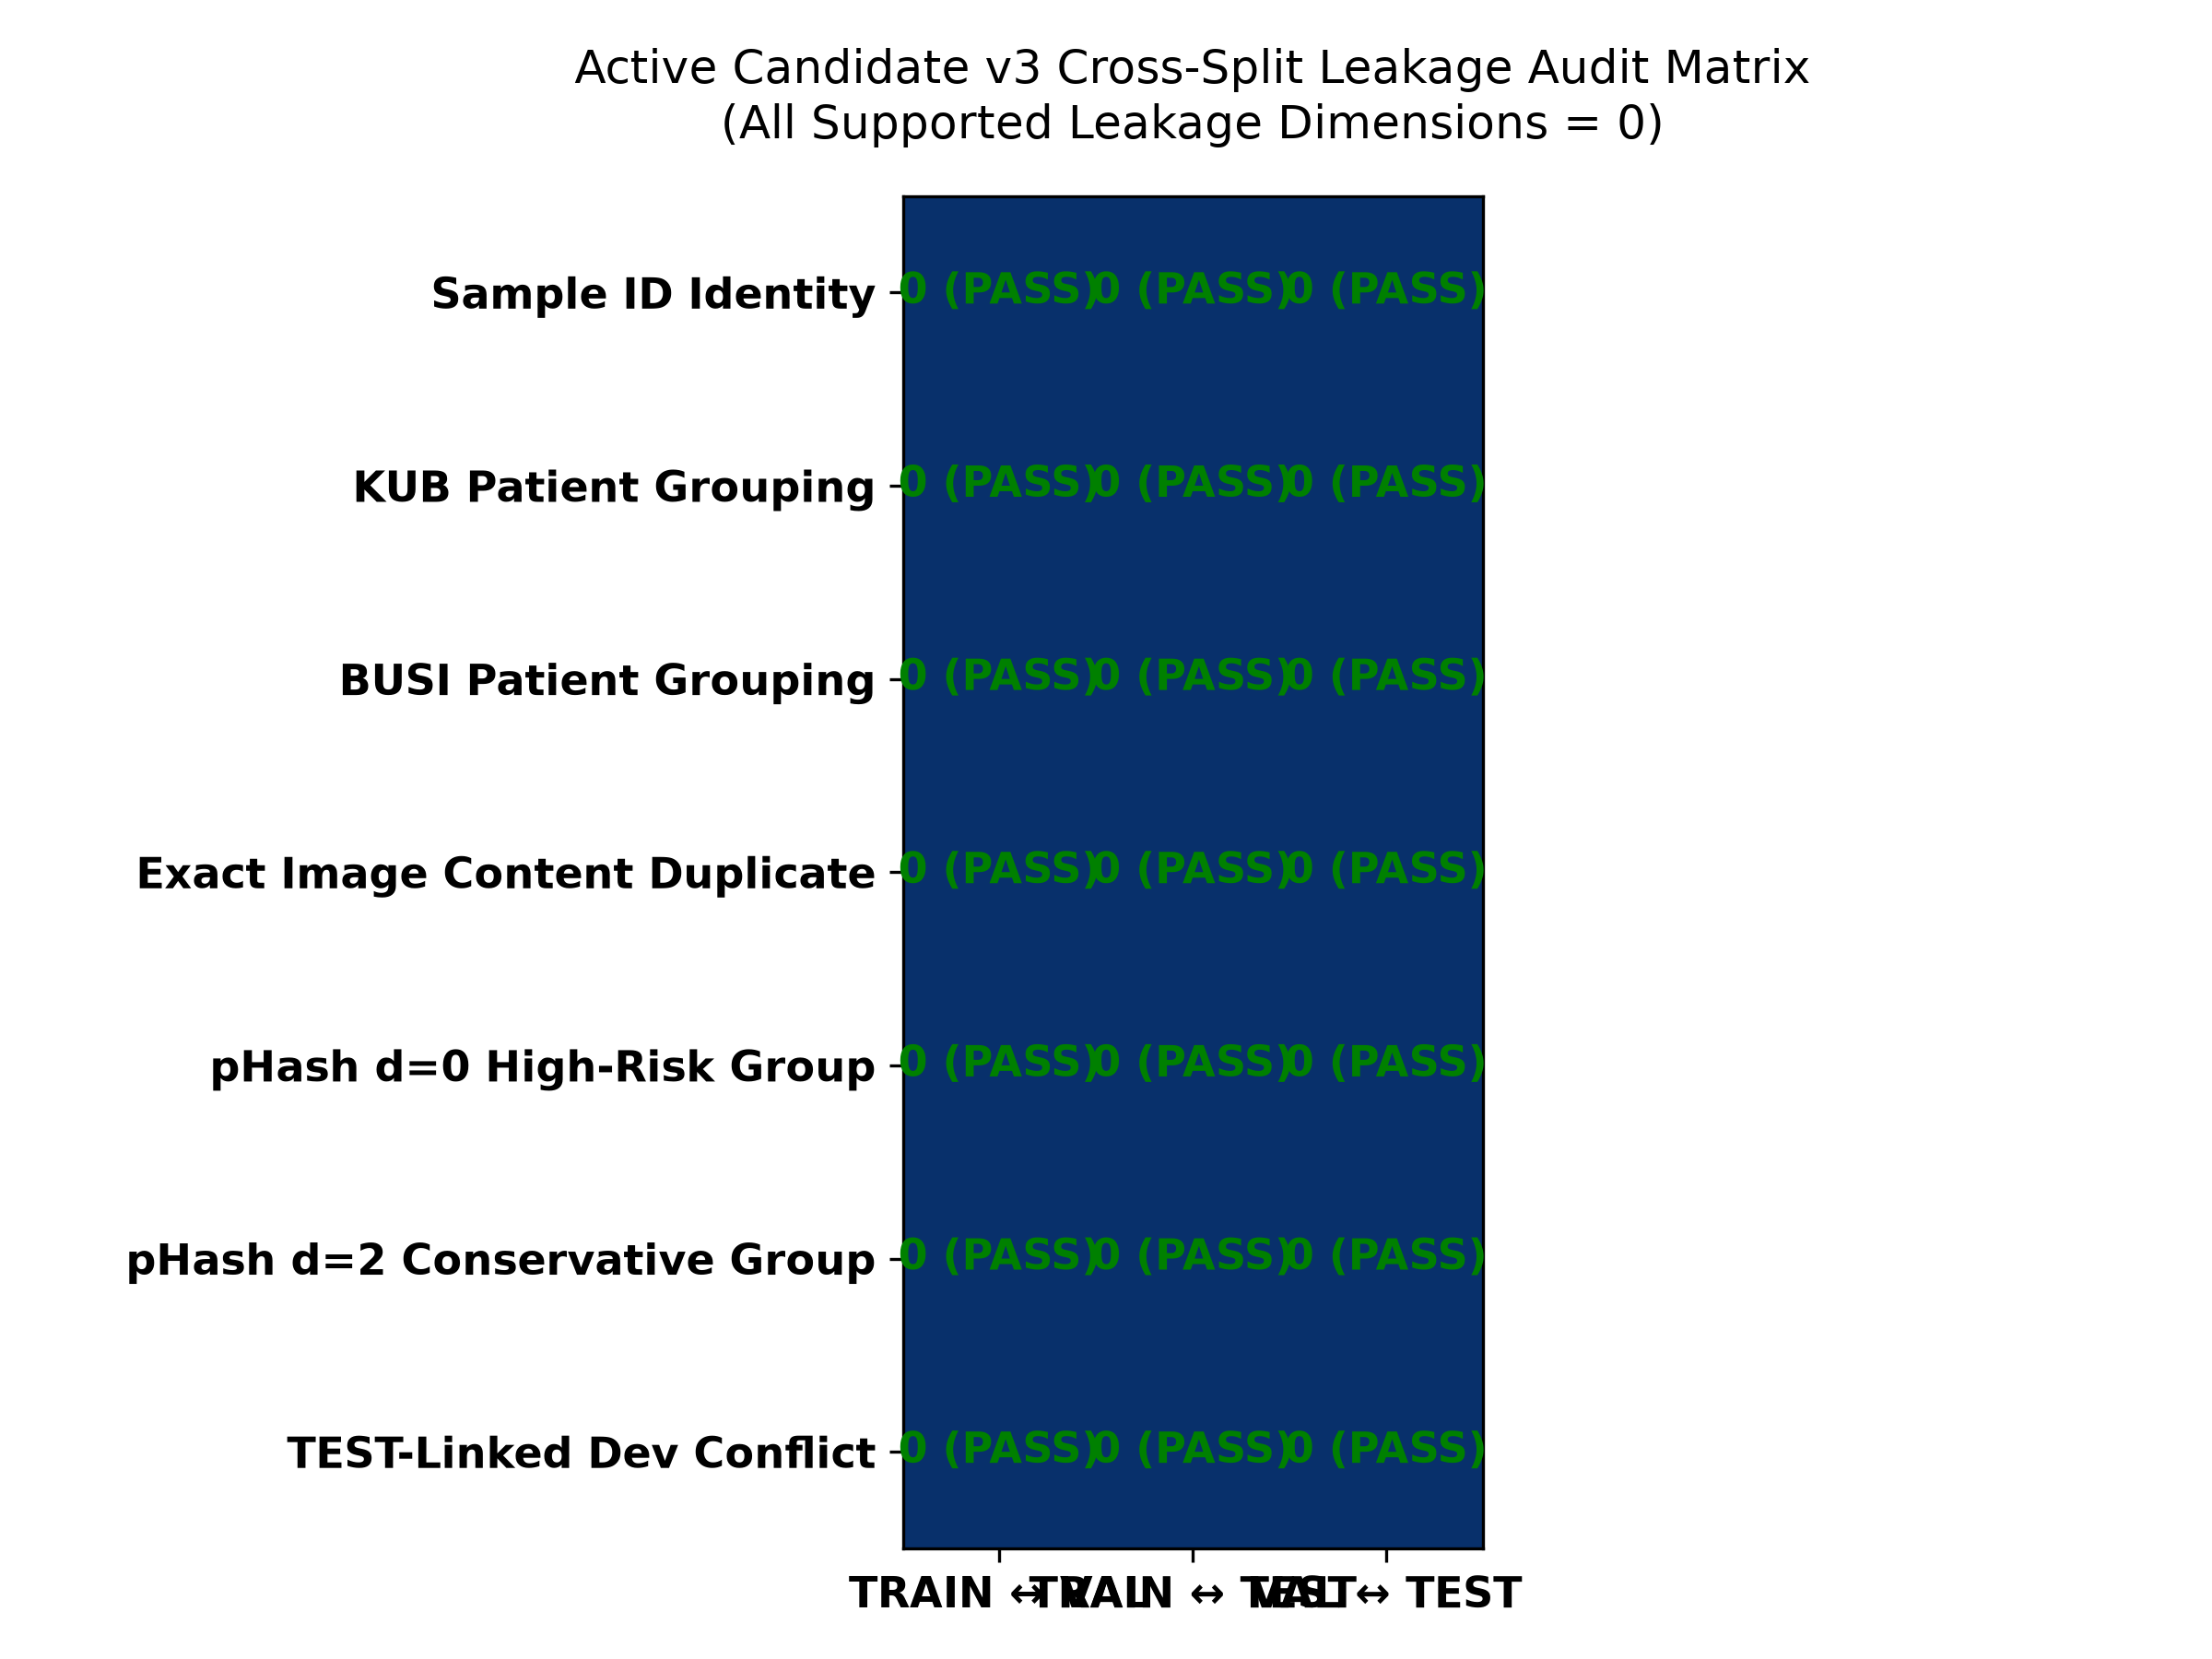

**Figure 4**: Leakage audit matrix across active candidate splits. Every supported dimension of cross-split contamination is strictly zero.

In [11]:
# Display Figure 4: Active Split Leakage Matrix
fig4_path = os.path.join(PROJECT_ROOT, 'reports/figures/phase05_leakage_audit/v3_candidate/phase05_v3_active_split_leakage_matrix.png')
display(Image(filename=fig4_path))
display(Markdown("**Figure 4**: Leakage audit matrix across active candidate splits. Every supported dimension of cross-split contamination is strictly zero."))

## 11. Active TRAIN↔VAL Raw Image Exact Content Recheck

To eliminate any possibility of remaining development image collisions, all active TRAIN images ($N=5,832$) and active VAL images ($N=808$) were rehashed byte-for-byte using SHA-256.
TEST images are **not** accessed or read.

In [12]:
# Recheck exact raw byte collisions between active TRAIN and VAL
exact_collisions = recheck_active_train_val_exact_duplicates(v3_data)
print(f"Active TRAIN↔VAL Raw Byte Collisions: {exact_collisions}")

assert exact_collisions == 0
display(Markdown("**TRAIN↔VAL EXACT CONTENT RECHECK: PASS (Zero Collisions in Active Development Splits)**"))

Active TRAIN↔VAL Raw Byte Collisions: 0


**TRAIN↔VAL EXACT CONTENT RECHECK: PASS (Zero Collisions in Active Development Splits)**

## 12. Dataset Population & Distribution Drift Audit

We compare v2 canonical splits vs candidate v3 splits across datasets, KUB categories, and view types to quantify distribution drift resulting from quarantining.

,dataset,v2_train,v3_train,train_delta,v2_val,v3_val,val_delta,test_immutable,quarantined_total
0,KUB,1979,1978,-1,283,280,-3,558,4
1,ISIC,2581,2556,-25,378,357,-21,735,46
2,BUSI,656,602,-54,97,84,-13,174,67
3,KVASIR,697,696,-1,87,87,0,216,1



KUB Active Categories:
  TRAIN: Kidney_Stone = 1133 | Bladder_Stone = 634 | Ureteric_Stone = 211
  VAL  : Kidney_Stone = 112 | Bladder_Stone = 144 | Ureteric_Stone = 24


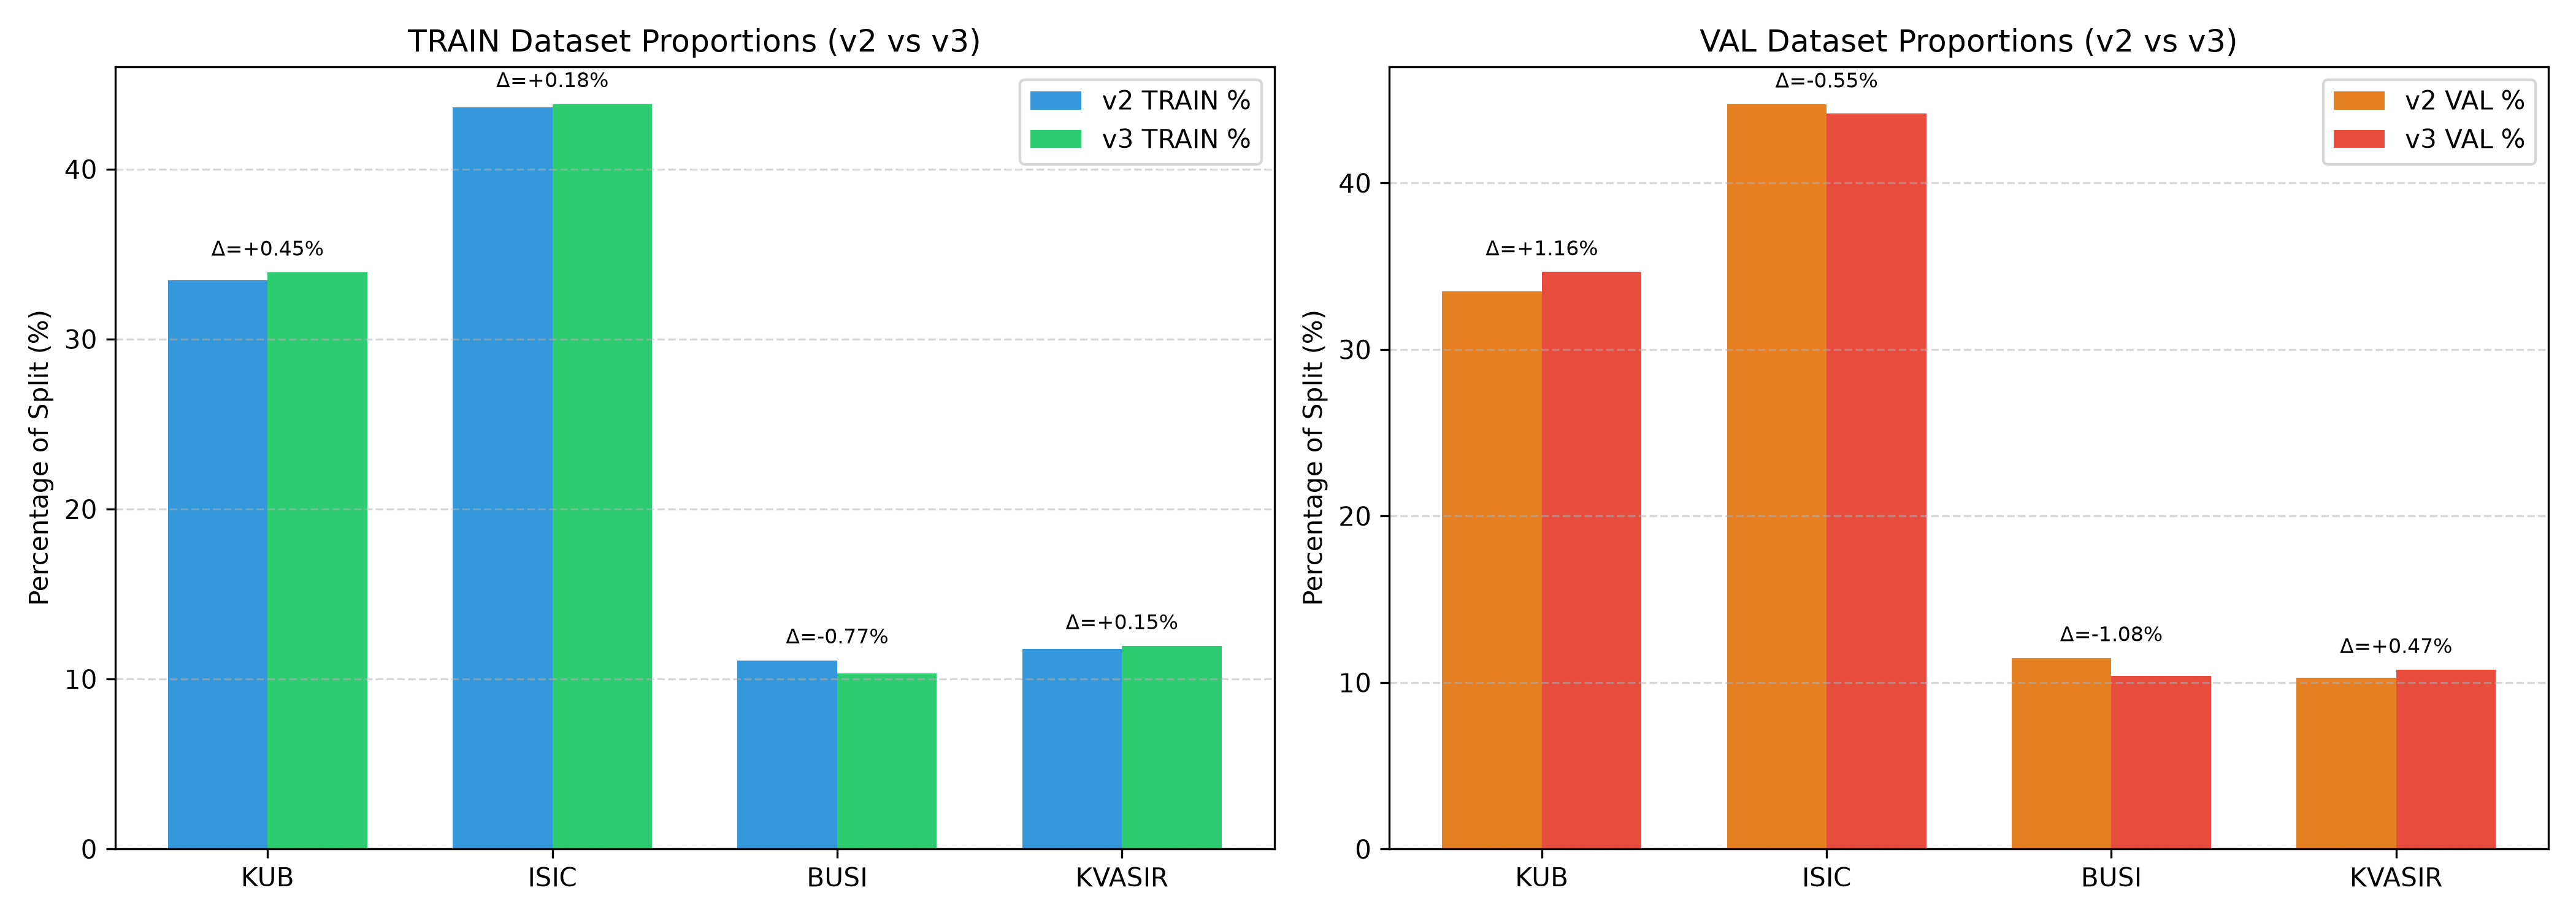

**Figure 5**: Dataset split proportions across v2 vs v3. Maximum observed drift is limited to +1.16 percentage points in KUB VAL, preserving representative multi-domain balance.

In [13]:
pop_comp_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'reports/tables/phase05_v3_dataset_split_comparison.csv'))
display(pop_comp_df)

# Check KUB category distribution
kub_v3_tr = v3_data['train'][v3_data['train']['dataset'] == 'KUB']
kub_v3_va = v3_data['val'][v3_data['val']['dataset'] == 'KUB']
print("\nKUB Active Categories:")
print("  TRAIN: Kidney_Stone =", (kub_v3_tr['category']=='Kidney_Stone').sum(),
      "| Bladder_Stone =", (kub_v3_tr['category']=='Bladder_Stone').sum(),
      "| Ureteric_Stone =", (kub_v3_tr['category']=='Ureteric_Stone').sum())
print("  VAL  : Kidney_Stone =", (kub_v3_va['category']=='Kidney_Stone').sum(),
      "| Bladder_Stone =", (kub_v3_va['category']=='Bladder_Stone').sum(),
      "| Ureteric_Stone =", (kub_v3_va['category']=='Ureteric_Stone').sum())

# Display Figure 5: Distribution Drift
fig5_path = os.path.join(PROJECT_ROOT, 'reports/figures/phase05_leakage_audit/v3_candidate/phase05_v3_distribution_drift.png')
display(Image(filename=fig5_path))
# Programmatic drift calculation
v2_val = v2_data['all'][v2_data['all']['split'] == 'VAL']
v3_val = v3_data['val']
datasets = ['KUB', 'ISIC', 'BUSI', 'KVASIR']
max_drift = 0
max_d_name = ""

for d in datasets:
    count_v2 = len(v2_val[v2_val['dataset'] == d])
    count_v3 = len(v3_val[v3_val['dataset'] == d])
    
    p_v2 = (count_v2 / len(v2_val)) * 100
    p_v3 = (count_v3 / len(v3_val)) * 100
    
    drift = p_v3 - p_v2
    if abs(drift) > abs(max_drift):
        max_drift = drift
        max_d_name = d

display(Markdown(f"**Figure 5**: Dataset split proportions across v2 vs v3. Maximum observed drift is limited to {max_drift:+.2f} percentage points in {max_d_name} VAL, preserving representative multi-domain balance."))

## 13. Phase 14 Protocol Clarification & Downstream Rerun Scope

### Protocol Truth & Clarification
- **Regional Refiner Training (Phase 14 Part 2)**: Trained on **A3 ground-truth-derived positive crops + perturbed GT crops + negative crops**. It was **NOT** trained directly on Stage-4D predicted proposal crops.
- **Regional Refiner Checkpoint Selection**: Evaluated on validation crops derived from the v2 validation set, which contained the contaminated KUB sample `a62708...`.
- **Predicted Mode Evaluation (Part 3)**: Inherited Stage-4D predicted proposals, but was strictly evaluated against frozen ground-truth masks.

### Clean Rerun Scope Under v3
If candidate v3 is promoted:
- **Phases 00–04**: Phase 04 manifest generation will be versioned to v3.
- **Phases 09–13**: Training and tuning pipelines will run on uncontaminated `train_v3_candidate.csv` and validate on `val_v3_candidate.csv`.
- **Phase 14**: Checkpoint selection will be conducted on uncontaminated validation crops.
- **Phase 39**: Internal untouched TEST evaluation will execute on immutable `test.csv`.

## Historical Pre-Lock TEST-Linked pHash High-Risk Reconciliation

Using the historical 
reports/audits/near_duplicate_candidates.csv pre-lock evidence, we identified candidate pairs across splits with a Hamming distance <= 2 involving the TEST split.

### Results
- **Source**: 
reports/audits/near_duplicate_candidates.csv
- **Total d<= 2 pairs**: 34
- **Unique development nodes linked to TEST**: 34
- **ISIC**: 31
- **KUB**: 2
- **KVASIR**: 1
- **BUSI**: 0
- **Already quarantined**: 0
- **Newly quarantined**: 34
- **Final remaining active**: 0

The 34 newly identified development samples are formally quarantined under QUARANTINED_TEST_LINKED_PHASH_HIGH_RISK.
TEST imagery remains absolutely intact (0 image reads).

*(Note: Remaining historical candidates at distances d=4 and d=6 are preserved as adjudicated diagnostic evidence. They are not automatically quarantined because they were largely classified as likely false positives under the frozen forensic review. They are documented but do not actively contaminate the v3 splits under the strict d<=2 prospective conservative high-risk threshold.)*

## 14. Master Artifact SHA-256 Provenance Registry

In [14]:
artifacts_to_hash = [
    ('Candidate all_paired', os.path.join(PROJECT_ROOT, 'manifests/phase4_v3_candidate/all_paired_v3_candidate.csv')),
    ('Candidate train', os.path.join(PROJECT_ROOT, 'manifests/phase4_v3_candidate/train_v3_candidate.csv')),
    ('Candidate val', os.path.join(PROJECT_ROOT, 'manifests/phase4_v3_candidate/val_v3_candidate.csv')),
    ('Candidate test', os.path.join(PROJECT_ROOT, 'manifests/phase4_v3_candidate/test_v3_candidate.csv')),
    ('Candidate quarantined', os.path.join(PROJECT_ROOT, 'manifests/phase4_v3_candidate/quarantined_v3_candidate.csv')),
    ('Candidate duplicate_groups', os.path.join(PROJECT_ROOT, 'manifests/phase4_v3_candidate/duplicate_groups_v3_candidate.csv')),
    ('Candidate grouping_provenance', os.path.join(PROJECT_ROOT, 'manifests/phase4_v3_candidate/grouping_provenance_v3_candidate.csv')),
    ('Candidate Audit JSON', os.path.join(PROJECT_ROOT, 'reports/audits/phase05_v3_candidate_manifest_audit.json')),
    ('BUSI Patient Group Mapping', os.path.join(PROJECT_ROOT, 'reports/tables/phase05_busi_patient_group_mapping.csv')),
    ('TEST-linked high-risk pHash pairs', os.path.join(PROJECT_ROOT, 'reports/tables/phase05_test_linked_high_risk_phash_pairs.csv')),
    ('TEST-linked high-risk Audit JSON', os.path.join(PROJECT_ROOT, 'reports/audits/phase05_v3_test_linked_high_risk_audit.json')),
    ('Build Script', os.path.join(PROJECT_ROOT, 'notebooks/phasewise/phase_05_leakage_audit/code/phase05_build_v3_candidate.py')),
    ('Validation Script', os.path.join(PROJECT_ROOT, 'notebooks/phasewise/phase_05_leakage_audit/code/phase05_validate_v3_candidate.py')),
    ('Visualization Script', os.path.join(PROJECT_ROOT, 'notebooks/phasewise/phase_05_leakage_audit/code/phase05_v3_visualization.py')),
]

hash_rows = []
for label, p in artifacts_to_hash:
    with open(p, 'rb') as f:
        h = hashlib.sha256(f.read()).hexdigest()
    hash_rows.append({'Artifact': label, 'Path': p, 'SHA-256': h})

hash_df = pd.DataFrame(hash_rows)
pd.set_option('display.max_colwidth', None)
display(hash_df)

,Artifact,Path,SHA-256
0,Candidate all_paired,D:\Softfors\jup\manifests/phase4_v3_candidate/all_paired_v3_candidate.csv,eb3062fa0e84f9952f994df79ed4d767417a912e18dce86560f6e2edcdd02ded
1,Candidate train,D:\Softfors\jup\manifests/phase4_v3_candidate/train_v3_candidate.csv,28702fc3a5ff8b950db372f03232d335e3a30b1fc2f21db7cd8c066055826ed6
2,Candidate val,D:\Softfors\jup\manifests/phase4_v3_candidate/val_v3_candidate.csv,082c80b2bda63fd73f371f109c34643adf01edaead921643fb2e44993ba53315
3,Candidate test,D:\Softfors\jup\manifests/phase4_v3_candidate/test_v3_candidate.csv,9361eba61c91c034a9aa4988a4df229bba591a5cbd553c98689ac7915da29727
4,Candidate quarantined,D:\Softfors\jup\manifests/phase4_v3_candidate/quarantined_v3_candidate.csv,a4ec1a8c46692f3c2d55d03c73569ce7b44aeeef734abd41e31bf5bf3e60059c
5,Candidate duplicate_groups,D:\Softfors\jup\manifests/phase4_v3_candidate/duplicate_groups_v3_candidate.csv,830d3c0ce08f735081e5a44fe3a740031da1c70cfc19ebcb4ef89c31acd704fb
6,Candidate grouping_provenance,D:\Softfors\jup\manifests/phase4_v3_candidate/grouping_provenance_v3_candidate.csv,3eff84851d33e1c8b5894ce05049433287067a5e6088a90f5c67394230317f66
7,Candidate Audit JSON,D:\Softfors\jup\reports/audits/phase05_v3_candidate_manifest_audit.json,a74f4d33bcb4fa282b66cd993d6810745601985cb3cf00cbb60295e2c53ec289
8,BUSI Patient Group Mapping,D:\Softfors\jup\reports/tables/phase05_busi_patient_group_mapping.csv,df4b01487ea6e1cb5c004e11535e4c3252c19dc3b84cbb21816c737dbaf2753b
9,TEST-linked high-risk pHash pairs,D:\Softfors\jup\reports/tables/phase05_test_linked_high_risk_phash_pairs.csv,3bed0ac2f541eb08b1252e7a8f37c40f7f39d218aead85549331abac11dfbc2e


## 15. Supervisor Gate Status & Recommendation

### Summary of Audit Gates
- [x] Population Conservation: $5,832 + 808 + 1,683 + 118 = 8,441$ (**PASS**)
- [x] Test Immutability: Byte-identical to canonical v2 `test.csv` (**PASS**)
- [x] Test Medical Content Reads: Exactly 0 (**PASS**)
- [x] KUB Exact Duplicate Resolved: Patient IDs distinct, VAL quarantined (**PASS**)
- [x] BUSI Clinical Disjointness: Active overlaps $= 0/0/0$ (**PASS**)
- [x] ISIC $d=0$ Grouping: Active cross-split groups $= 0$ (**PASS**)
- [x] $d=2$ Graph Accounting: 4 pairs $\rightarrow$ 3 unique VAL quarantined rows (**PASS**)
- [x] Active TRAIN↔VAL Exact Content Duplicates: Exactly 0 (**PASS**)
- [x] Embedded Figure Count: $\ge 5$ figures rendered (**PASS**)

### Status Recommendation
**SCIENTIFIC GATE**: **CHECK_REQUIRED**
The v3 data governance manifests remain strictly a **CANDIDATE PACKAGE**.
No promotion to canonical status has been performed. Awaiting explicit supervisor authorization before initiating Phase 06.